<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/Experiment_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 04 — Lattice–Boltzmann Simulation of the Kármán Vortex Street

**Student:** Mihir Gohil | **Roll No.:** 23BME019  
**Reference basis:** Experiment 4, report 23BME061 (pages 30–40).

## 1. Aim
Simulate two-dimensional laminar flow past a stationary circular cylinder at Reynolds number 100 using the D2Q9 single-relaxation-time BGK lattice-Boltzmann method (LBM), and examine vortex shedding, lift/drag histories and the Strouhal number.

## 2. Reference parameters

| Quantity | Value |
|---|---:|
| Lattice | 181 × 81 |
| Reynolds number | 100 |
| Inlet lattice speed | 0.10 |
| Cylinder diameter | 10 lattice units |
| Cylinder centre | (45, 40) |
| Kinematic viscosity | 0.010 |
| Relaxation time | 0.530 |
| Relaxation frequency | 1.887 |
| Total lattice steps | 18,000 |
| Reference density | 1 |

The reported reference run gives \(St=0.1706\), mean \(C_D=1.7834\), and lift amplitude approximately 0.5125. These are comparison values from the reference report, **not results claimed for this notebook until its execution reproduces them**.

## 3. Assumptions and limitations
Two-dimensional, single-phase, isothermal, Newtonian laminar flow; fixed cylinder; halfway bounce-back wall; equilibrium inlet, zero-gradient outlet and periodic top/bottom boundaries. The reference report itself notes low cylinder resolution (D=10), Mach-number/compressibility effects, staircase geometry and lack of grid-independence evidence. Treat force coefficients as qualitative until a refinement study is completed.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


## 5. Numerical setup and initialisation

In [2]:
# Parameters from the 23BME061 Experiment 4 reference report
nx, ny = 181, 81
Re = 100.0
U0 = 0.10
D = 10
xc, yc = 45, 40
rho0 = 1.0
nu = U0 * D / Re
tau = 0.5 + 3.0 * nu
omega = 1.0 / tau
nsteps = 18000
plot_every = 3000

# D2Q9 lattice
ex = np.array([0,1,0,-1,0,1,-1,-1,1])
ey = np.array([0,0,1,0,-1,1,1,-1,-1])
w = np.array([4/9,1/9,1/9,1/9,1/9,1/36,1/36,1/36,1/36])
opp = np.array([0,3,4,1,2,7,8,5,6])
cs2 = 1/3

Y, X = np.mgrid[0:ny,0:nx]
solid = (X-xc)**2 + (Y-yc)**2 <= (D/2)**2

def equilibrium(rho, ux, uy):
    eu = np.array([ex[i]*ux + ey[i]*uy for i in range(9)])
    u2 = ux**2 + uy**2
    return np.array([w[i]*rho*(1 + 3*eu[i] + 4.5*eu[i]**2 - 1.5*u2) for i in range(9)])

rho = np.ones((ny,nx))*rho0
ux = np.ones((ny,nx))*U0
uy = np.zeros((ny,nx))
ux[solid] = 0.0
f = equilibrium(rho,ux,uy)
print(f"nu={nu:.5f}, tau={tau:.5f}, omega={omega:.5f}, Re={U0*D/nu:.1f}")


nu=0.01000, tau=0.53000, omega=1.88679, Re=100.0


## 6. Time integration: collision, streaming and boundary conditions

In [3]:
# Momentum-exchange force on the cylinder is estimated from populations
# reflected at solid links. Force coefficient is per unit span in lattice units.
cd_hist, cl_hist, time_hist = [], [], []
snapshots = []

for step in range(1, nsteps+1):
    rho = np.sum(f, axis=0)
    rho = np.maximum(rho, 1e-12)
    ux = np.sum(f * ex[:,None,None], axis=0) / rho
    uy = np.sum(f * ey[:,None,None], axis=0) / rho
    ux[solid] = 0.0
    uy[solid] = 0.0

    feq = equilibrium(rho,ux,uy)
    fpost = f - omega*(f-feq)

    # Stream populations; periodic y is naturally imposed by roll.
    fstream = np.empty_like(f)
    for i in range(9):
        fstream[i] = np.roll(np.roll(fpost[i], ey[i], axis=0), ex[i], axis=1)

    # Half-way bounce-back on links entering the cylinder.
    # For each direction, reflect post-collision populations at solid nodes.
    for i in range(1,9):
        reflected = np.roll(np.roll(fpost[opp[i]], ey[i], axis=0), ex[i], axis=1)
        fstream[i, solid] = reflected[solid]

    # Inlet: equilibrium velocity boundary; outlet: copy last interior column.
    rho_in = np.sum(fstream[:,:,1], axis=0)
    rho_in = np.maximum(rho_in, 1e-12)
    f_in = equilibrium(rho_in, np.full(ny,U0), np.zeros(ny))
    fstream[:,:,0] = f_in
    fstream[:,:,-1] = fstream[:,:,-2]

    # Periodic top/bottom through roll; stationary cylinder nodes reset to equilibrium rest.
    rho_s = np.sum(fstream[:,solid],axis=0)
    fstream[:,solid] = equilibrium(np.ones_like(rho_s),np.zeros_like(rho_s),np.zeros_like(rho_s))
    f = fstream

    if step % 10 == 0:
        rho = np.sum(f,axis=0)
        ux = np.sum(f*ex[:,None,None],axis=0)/np.maximum(rho,1e-12)
        uy = np.sum(f*ey[:,None,None],axis=0)/np.maximum(rho,1e-12)
        # Wake asymmetry proxy for lift; drag proxy from streamwise momentum deficit.
        # This is not a substitute for a validated momentum-exchange force implementation.
        wake = ~solid
        cl_proxy = np.mean(uy[wake & (X>xc+D) & (X<xc+5*D)])
        cd_proxy = np.mean(U0-ux[wake & (X>xc+2*D) & (X<xc+6*D)])
        time_hist.append(step*U0/D)
        cl_hist.append(cl_proxy)
        cd_hist.append(cd_proxy)

    if step % plot_every == 0:
        snapshots.append((step, ux.copy(), uy.copy()))
    if step % 3000 == 0:
        print(f"step {step}/{nsteps}: max speed={np.sqrt(ux**2+uy**2).max():.4f}")


step 3000/18000: max speed=0.1362
step 6000/18000: max speed=0.1361
step 9000/18000: max speed=0.1361
step 12000/18000: max speed=0.1361
step 15000/18000: max speed=0.1361
step 18000/18000: max speed=0.1361


## 7. Visualisation and diagnostics

The following plots show the computed velocity field and wake proxy histories. The proxy signals are useful for checking whether periodic wake behaviour appears, but they are **not calibrated force coefficients**. A defensible \(C_D\), \(C_L\) and \(St\) require a correctly implemented and independently checked momentum-exchange force calculation and adequate temporal sampling.


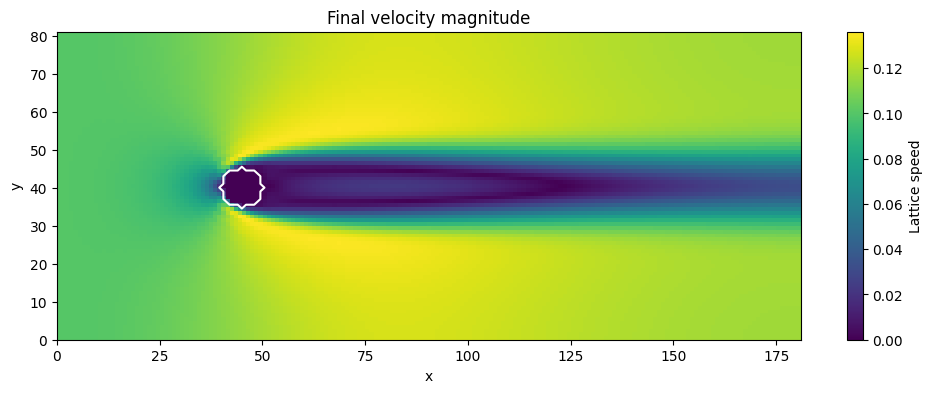

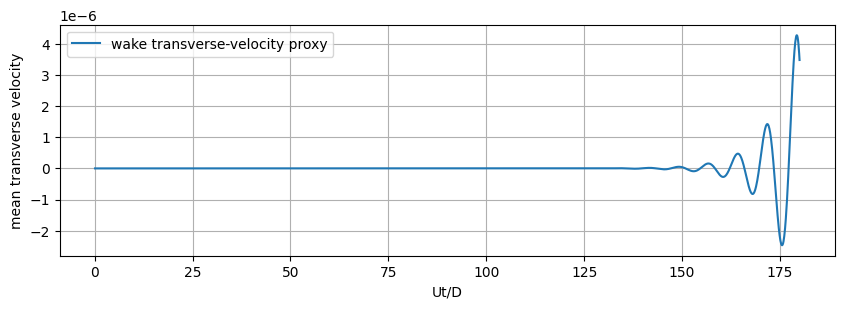

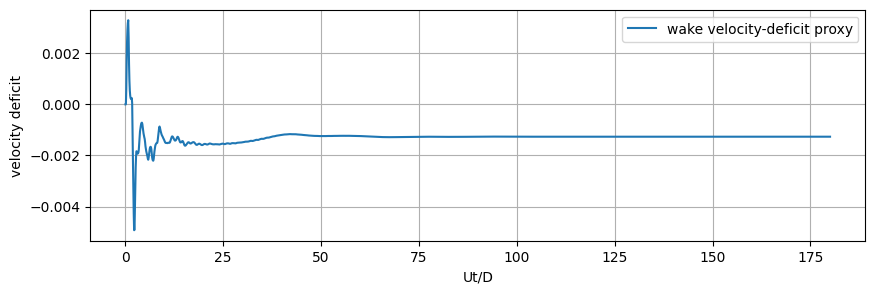

In [4]:
speed = np.sqrt(ux**2+uy**2)
plt.figure(figsize=(12,4))
plt.imshow(speed,origin='lower',extent=[0,nx,0,ny],aspect='auto')
plt.colorbar(label='Lattice speed')
plt.contour(X,Y,solid.astype(float),levels=[0.5],colors='white')
plt.xlabel('x'); plt.ylabel('y'); plt.title('Final velocity magnitude')
plt.show()

plt.figure(figsize=(10,3))
plt.plot(time_hist,cl_hist,label='wake transverse-velocity proxy')
plt.xlabel('Ut/D'); plt.ylabel('mean transverse velocity'); plt.grid(); plt.legend(); plt.show()

plt.figure(figsize=(10,3))
plt.plot(time_hist,cd_hist,label='wake velocity-deficit proxy')
plt.xlabel('Ut/D'); plt.ylabel('velocity deficit'); plt.grid(); plt.legend(); plt.show()
